# Does better volatility forecasting give better risk numbers?

This notebook runs the whole project top to bottom: data, portfolio, five 1-day VaR models
(historical simulation 250/500, EWMA, GARCH-normal, GARCH-t), backtests the way a bank's
risk-control team would, Expected Shortfall, a regime split and the Siemens sensitivity run.

All parameters live in `config.py`; the logic lives in `src/`. Look for `# DECISION:` and
`# PITFALL:` comments in the code (summarised in `LEARNING_NOTES.md`).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # project root, so `config` and `src` import

import pandas as pd
from IPython.display import Image, display

import config
from run_all import (build_forecasts, compare_sensitivity, confidence_of,
                     garch_min_window_check, run_backtests)
from src import backtest, data, plots, portfolio

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
REFRESH = False  # True = download fresh data and save a new snapshot

## 1. Data
Prices come from a saved snapshot in `data/raw/` (not in git, see README). Dates are aligned with an
inner join: a day is kept only if all five stocks have a price. Nothing is forward-filled.

In [2]:
raw, snapshot = data.load_prices(config.TICKERS + [config.BENCHMARK_TICKER], config.START_DATE,
                                 config.END_DATE, config.RAW_DATA_DIR, refresh=REFRESH)
prices, n_dropped = data.align_prices(raw[config.TICKERS])
stock_returns = data.compute_returns(prices)
print(f"Snapshot: {snapshot.name}")
print(f"Dates dropped by inner join: {n_dropped}")
print(f"Prices from {prices.index[0].date()} to {prices.index[-1].date()} ({len(prices)} days)")

Snapshot: prices_2026-10-19.csv
Dates dropped by inner join: 0
Prices from 2015-01-02 to 2026-10-16 (2998 days)


## 2. Data quality check
Every single-day stock return above 15% in absolute value is listed for manual review. Nothing is
changed automatically. The Siemens Energy spin-off (first trading day 28 Sep 2020) gets a closer look:
Siemens shows +9.22% that day while the DAX rose 3.22%, which suggests an inconsistent adjustment in
the Yahoo data. It stays in the main results and is tested in a sensitivity run at the end.

In [3]:
flagged = data.quality_check(stock_returns, config.QUALITY_RETURN_THRESHOLD)
flagged.style.format({"return": "{:.2%}"})

,Date,Ticker,return
0,2020-03-12 00:00:00,ALV.DE,-15.33%
1,2020-03-24 00:00:00,ALV.DE,15.80%
2,2020-10-26 00:00:00,SAP.DE,-21.94%
3,2026-01-29 00:00:00,SAP.DE,-16.07%


In [4]:
dax_returns = data.compute_returns(raw[[config.BENCHMARK_TICKER]].loc[prices.index])
data.inspect_window(stock_returns.join(dax_returns), [config.SIEMENS_TICKER, config.BENCHMARK_TICKER],
                    "2020-09-21", "2020-10-02").style.format("{:.2%}")

,SIE.DE,^GDAXI
Date,,
2020-09-21 00:00:00,-4.66%,-4.37%
2020-09-22 00:00:00,0.77%,0.41%
2020-09-23 00:00:00,-0.60%,0.39%
2020-09-24 00:00:00,1.03%,-0.29%
2020-09-25 00:00:00,-1.60%,-1.09%
2020-09-28 00:00:00,9.22%,3.22%
2020-09-29 00:00:00,-1.20%,-0.35%
2020-09-30 00:00:00,-0.70%,-0.51%
2020-10-01 00:00:00,-1.13%,-0.23%


## 3. Portfolio
Equal weights (20% each), rebalanced daily, so the portfolio return is the weighted sum of the
stocks' simple returns.

In [5]:
port = portfolio.portfolio_returns(stock_returns, config.WEIGHTS)
port.describe().to_frame().T

,count,mean,std,min,25%,50%,75%,max
portfolio,2997.0,0.000536,0.012212,-0.120303,-0.005164,0.000839,0.006776,0.10088


## 4. VaR and ES forecasts
Every forecast for day *t* uses returns up to *t-1* only. All models are evaluated on the **same**
period, starting on the first day every model has a forecast (set by the 500-day burn-in of HS500
and GARCH). GARCH is re-estimated every 20 days on a rolling 1000-day window.

In [6]:
var_df, es_df, garch_params, first_valid = build_forecasts(port)
r = port.loc[var_df.index]
print(f"Common backtest period: {var_df.index[0].date()} to {var_df.index[-1].date()} "
      f"({len(var_df)} days)")
first_valid.map(lambda d: d.date()).to_frame("first forecast")

Common backtest period: 2016-12-20 to 2026-10-16 (2497 days)


,first forecast
HS250_95,2015-12-28
HS500_95,2016-12-20
EWMA_95,2015-12-28
GARCH-N_95,2016-12-20
GARCH-t_95,2016-12-20
HS250_97.5,2015-12-28
HS500_97.5,2016-12-20
EWMA_97.5,2015-12-28
GARCH-N_97.5,2016-12-20
GARCH-t_97.5,2016-12-20


GARCH-N: 125 refits, 0 convergence failures, alpha+beta 0.838-0.991
GARCH-t: 125 refits, 0 convergence failures, alpha+beta 0.815-1.000


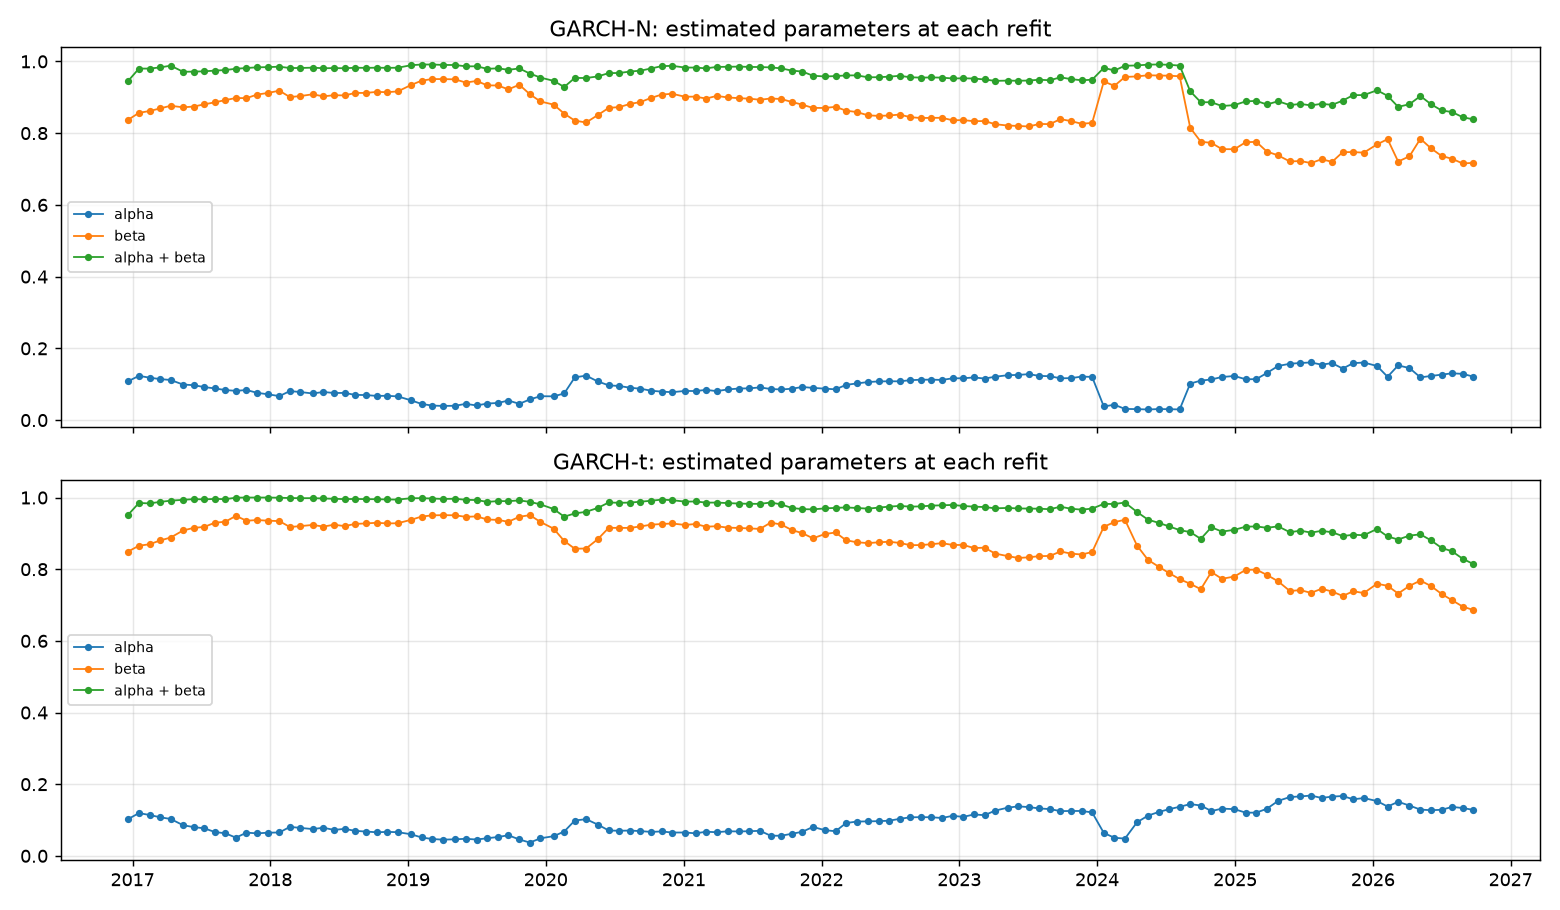

In [7]:
for name, p in garch_params.items():
    print(f"{name}: {len(p)} refits, {(~p['converged']).sum()} convergence failures, "
          f"alpha+beta {p['persistence'].min():.3f}-{p['persistence'].max():.3f}")
plots.plot_garch_params(garch_params, config.OUTPUT_DIR / "garch_parameters.png")
display(Image(config.OUTPUT_DIR / "garch_parameters.png"))

## 5. Backtests
For each model and confidence level: breaches, Kupiec proportion-of-failures test, Christoffersen
independence and conditional coverage tests, and for 99% the Basel traffic light
(rolling 250-day breach count: green 0-4, yellow 5-9, red 10+).

In [8]:
res = run_backtests(port, var_df)
table = res["table"]
table.style.format({"confidence": "{:.0%}", "expected_breaches": "{:.1f}", "breach_rate": "{:.2%}",
                    "kupiec_LR": "{:.2f}", "kupiec_p": "{:.3f}", "ind_LR": "{:.2f}",
                    "ind_p": "{:.3f}", "cc_LR": "{:.2f}", "cc_p": "{:.3f}",
                    "basel_latest_count": "{:.0f}", "share_green": "{:.0%}",
                    "share_yellow": "{:.0%}", "share_red": "{:.0%}"}, na_rep="")

,model,confidence,n_obs,expected_breaches,actual_breaches,breach_rate,kupiec_LR,kupiec_p,kupiec_reject,n11,ind_LR,ind_p,ind_reject,cc_LR,cc_p,cc_reject,basel_latest_count,basel_latest_zone,share_green,share_yellow,share_red
0,HS250,95%,2497,124.9,141,5.65%,2.11,0.146,False,17,9.00,0.003,True,11.11,0.004,True,,,,,
1,HS500,95%,2497,124.9,121,4.85%,0.13,0.722,False,18,18.81,0.000,True,18.94,0.000,True,,,,,
2,EWMA,95%,2497,124.9,148,5.93%,4.28,0.039,True,15,4.22,0.040,True,8.49,0.014,True,,,,,
3,GARCH-N,95%,2497,124.9,130,5.21%,0.22,0.638,False,15,8.56,0.003,True,8.78,0.012,True,,,,,
4,GARCH-t,95%,2497,124.9,142,5.69%,2.38,0.123,False,14,4.10,0.043,True,6.48,0.039,True,,,,,
5,HS250,99%,2497,25.0,34,1.36%,2.96,0.085,False,3,6.53,0.011,True,9.50,0.009,True,0,green,59%,35%,6%
6,HS500,99%,2497,25.0,37,1.48%,5.10,0.024,True,4,9.67,0.002,True,14.77,0.001,True,2,green,68%,21%,11%
7,EWMA,99%,2497,25.0,57,2.28%,30.45,0.000,True,3,1.72,0.190,False,32.17,0.000,True,5,yellow,21%,70%,9%
8,GARCH-N,99%,2497,25.0,46,1.84%,14.33,0.000,True,3,3.49,0.062,False,17.82,0.000,True,5,yellow,40%,49%,11%
9,GARCH-t,99%,2497,25.0,29,1.16%,0.62,0.429,False,1,0.88,0.348,False,1.51,0.471,False,3,green,81%,19%,0%


Breaches per calendar year show the clustering in 2020 (Covid) and 2022.

In [9]:
res["per_year"]

,HS250_95,HS500_95,EWMA_95,GARCH-N_95,GARCH-t_95,HS250_99,HS500_99,EWMA_99,GARCH-N_99,GARCH-t_99
year,,,,,,,,,,
2016,0,0,0,0,0,0,0,0,0,0
2017,11,0,16,7,12,3,0,2,0,0
2018,21,26,21,19,21,5,6,6,6,3
2019,11,12,14,13,14,2,3,7,5,2
2020,22,26,16,18,20,8,15,10,12,8
2021,10,4,13,13,13,1,1,6,4,3
2022,15,13,13,15,15,4,1,6,6,4
2023,9,4,14,10,11,1,0,6,2,2
2024,17,9,16,13,12,4,1,5,1,0


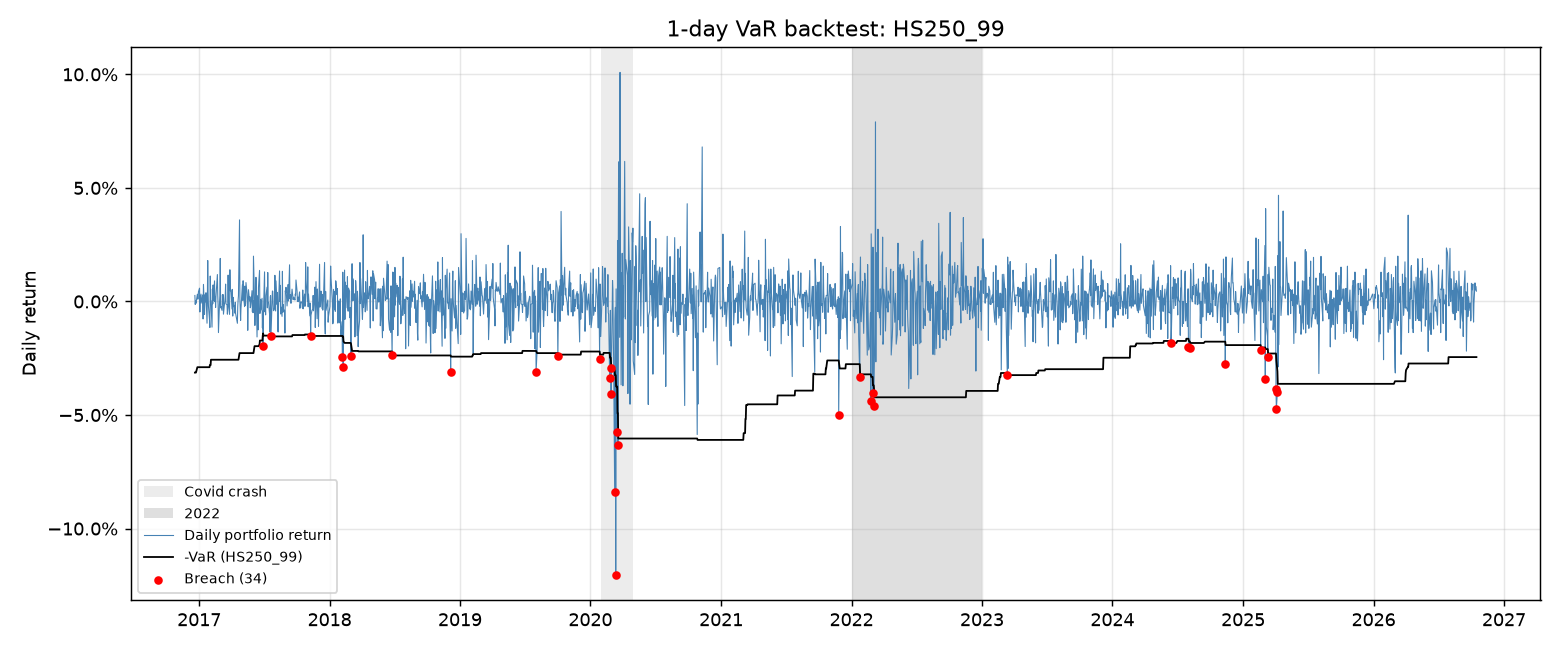

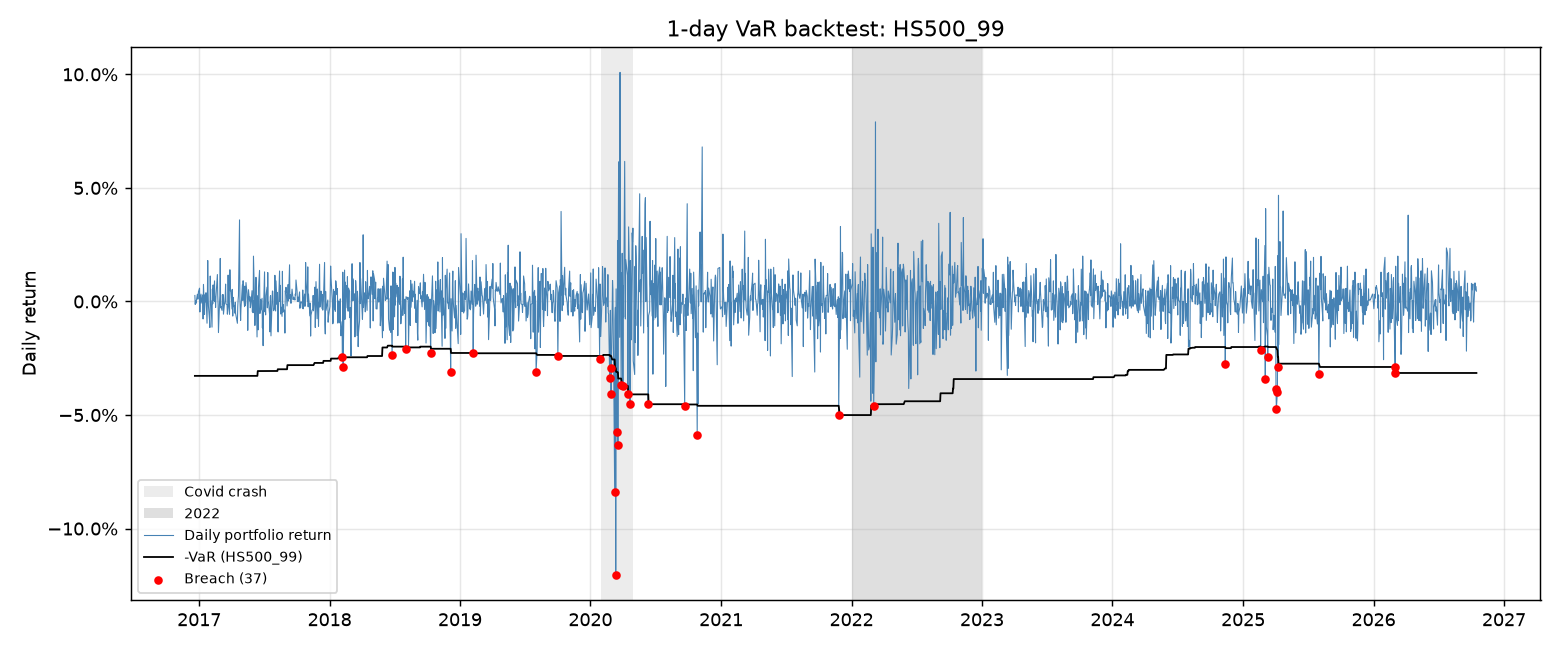

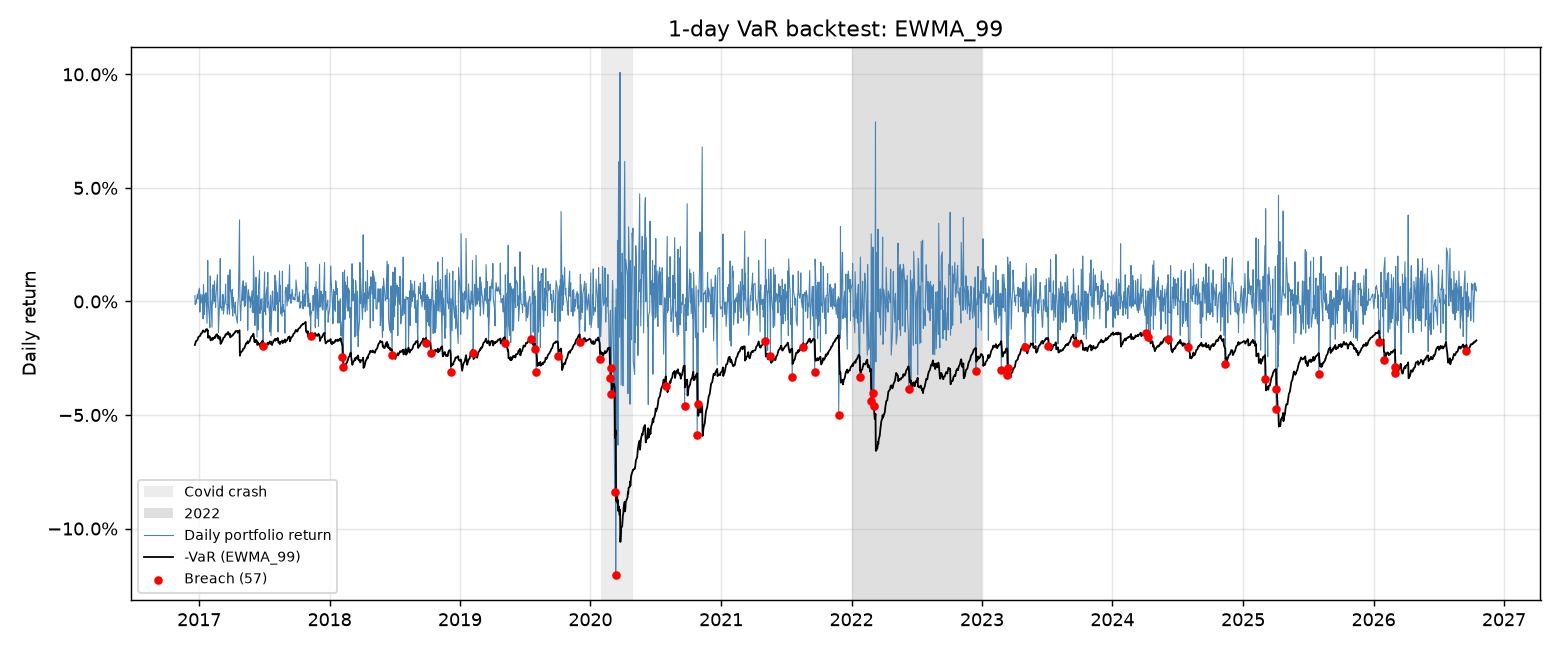

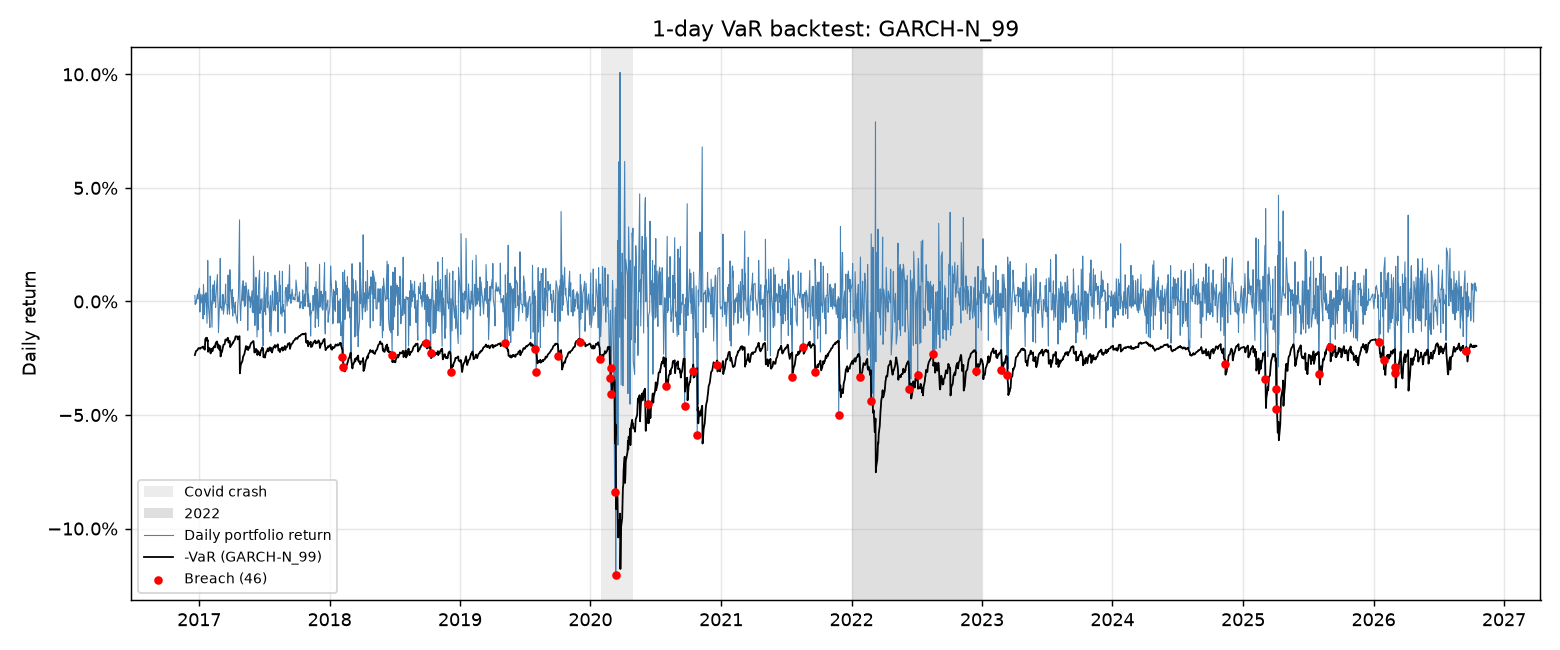

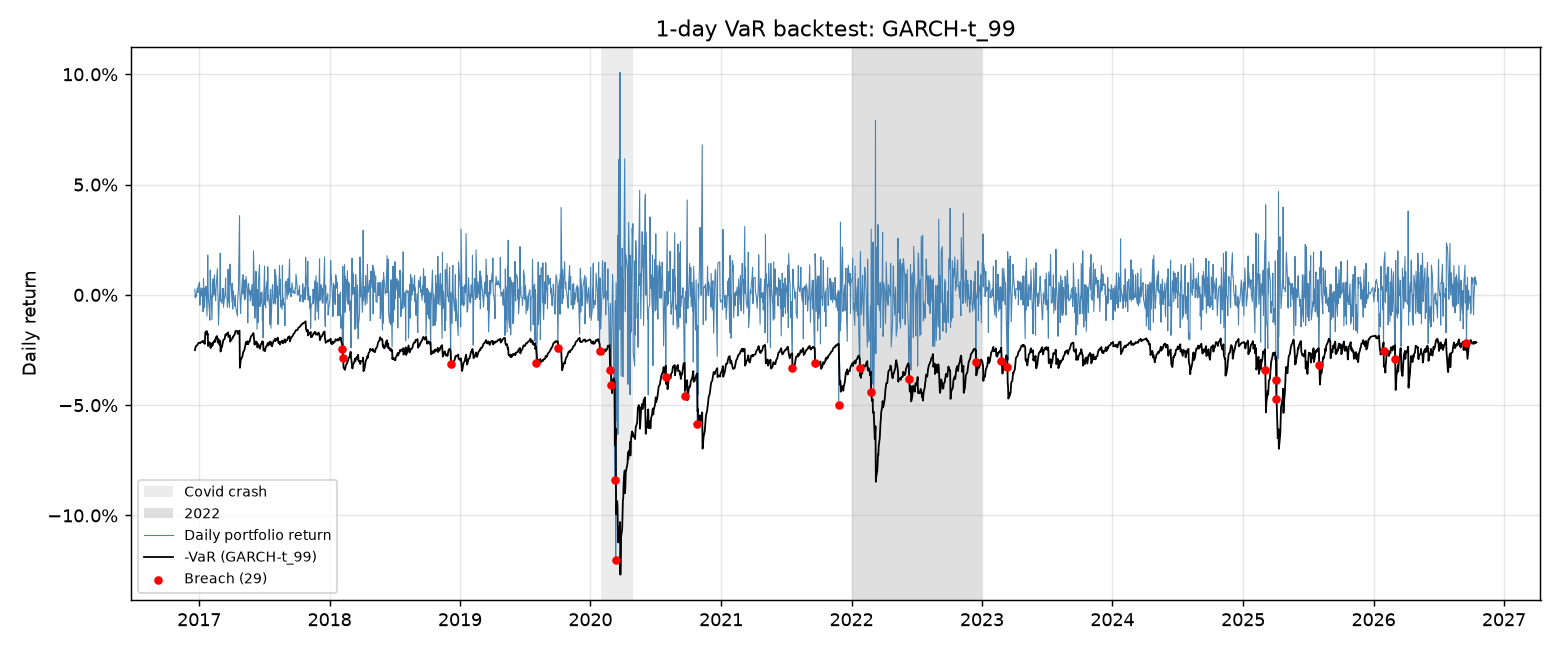

In [10]:
cols_99 = [c for c in var_df.columns if c.endswith("_99")]
for c in cols_99:
    path = config.OUTPUT_DIR / f"breaches_{c}.png"
    plots.plot_var_breaches(r, var_df[c], f"1-day VaR backtest: {c}", config.SHADED_PERIODS, path)
    display(Image(path))

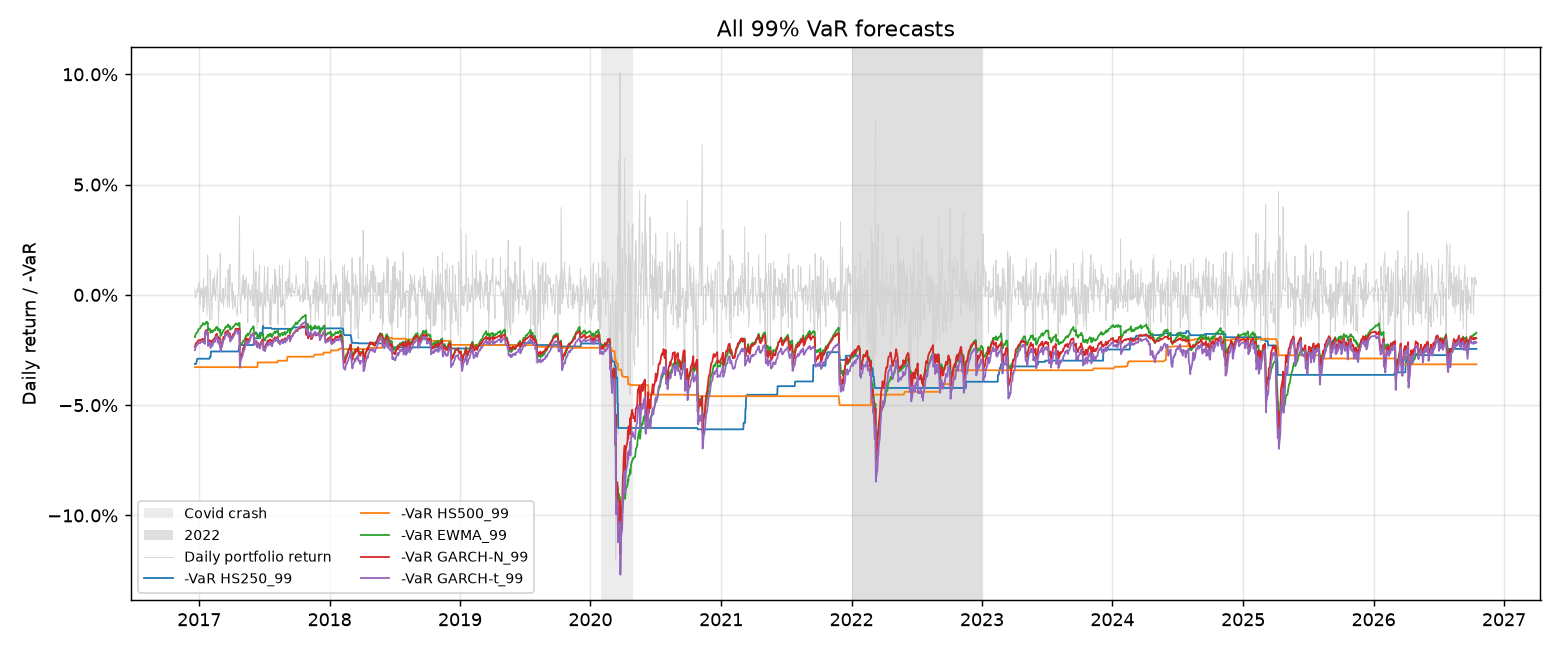

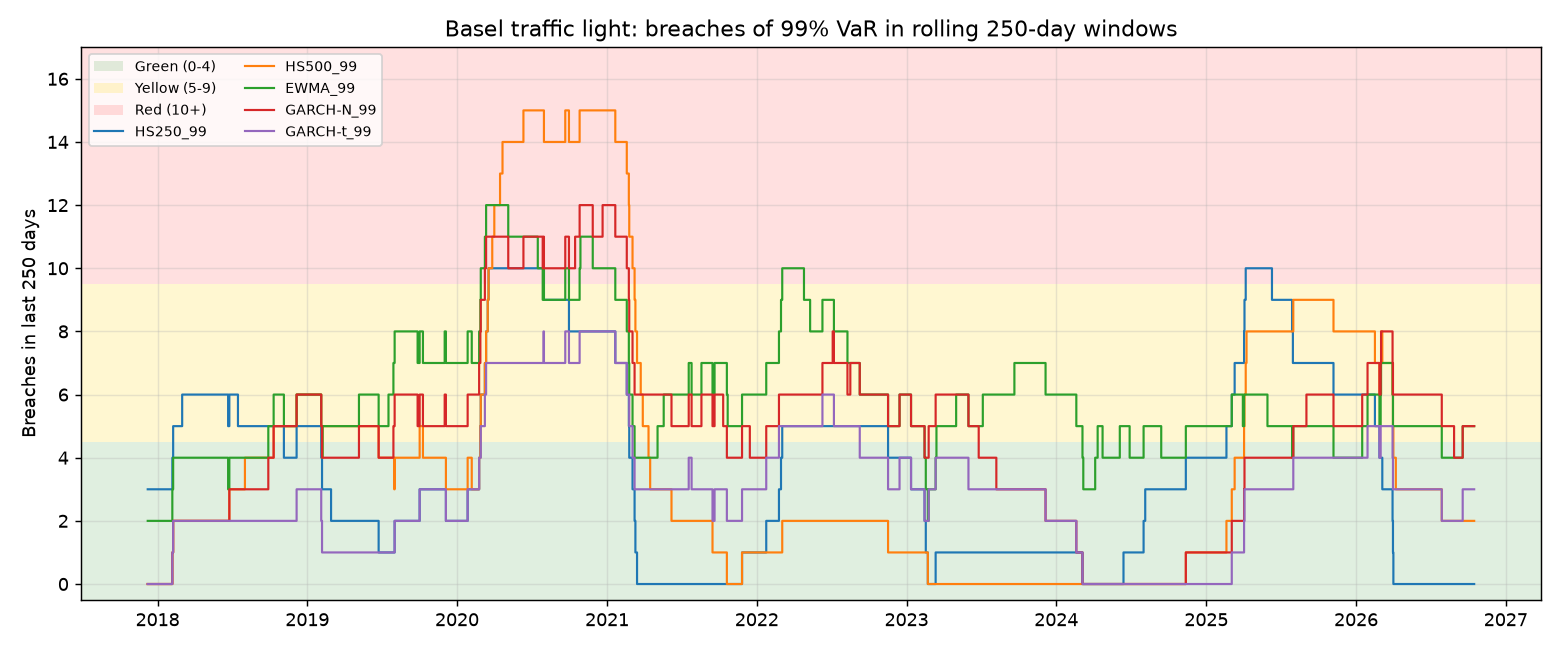

In [11]:
plots.plot_var_comparison(r, var_df[cols_99], "All 99% VaR forecasts", config.SHADED_PERIODS,
                          config.OUTPUT_DIR / "var_comparison_99.png")
plots.plot_traffic_light(res["tl_counts"], config.BASEL_GREEN_MAX, config.BASEL_YELLOW_MAX,
                         "Basel traffic light: breaches of 99% VaR in rolling 250-day windows",
                         config.OUTPUT_DIR / "traffic_light_99.png")
display(Image(config.OUTPUT_DIR / "var_comparison_99.png"))
display(Image(config.OUTPUT_DIR / "traffic_light_99.png"))

## 6. Expected Shortfall check
On the VaR breach days at the same level, compare the average realised loss with the average ES
forecast. A ratio above 1 means tail losses were worse than predicted. This is a plausibility check,
not a formal test (see the PITFALL in `backtest.es_check`).

In [12]:
es_table = pd.DataFrame([{"model": c.rsplit("_", 1)[0], "confidence": confidence_of([c])[c],
                          **backtest.es_check(r, var_df[c], es_df[c])} for c in es_df.columns])
es_table.style.format({"confidence": "{:.1%}", "avg_realised_loss": "{:.2%}",
                       "avg_es_forecast": "{:.2%}", "ratio": "{:.2f}"})

,model,confidence,n_breaches,avg_realised_loss,avg_es_forecast,ratio
0,HS250,97.5%,78,3.04%,2.90%,1.05
1,HS500,97.5%,71,3.29%,3.19%,1.03
2,EWMA,97.5%,96,2.68%,2.28%,1.18
3,GARCH-N,97.5%,81,2.90%,2.48%,1.17
4,GARCH-t,97.5%,74,2.97%,2.95%,1.01
5,HS250,99.0%,34,3.61%,3.14%,1.15
6,HS500,99.0%,37,3.90%,4.21%,0.93
7,EWMA,99.0%,57,3.13%,2.67%,1.17
8,GARCH-N,99.0%,46,3.40%,2.86%,1.19
9,GARCH-t,99.0%,29,3.92%,3.87%,1.01


## 7. Calm vs turbulent periods (descriptive)
A day is "turbulent" if the 60-day rolling volatility (up to *t-1*) is above its long-run median
(also up to *t-1*). The rule was fixed in advance and not tuned.

In [13]:
res["regimes"].pivot_table(index=["confidence", "model"], columns="regime", values="breach_rate",
                           sort=False).style.format("{:.2%}")

## 8. Siemens spin-off sensitivity
Replace the single SIE.DE return on 28 Sep 2020 with the DAX return of the same day, re-run every
model and backtest, and check whether any breach count, test decision or traffic-light result changes.

In [14]:
day = pd.Timestamp(config.SIEMENS_SPINOFF_DAY)
stock_alt = data.replace_return(stock_returns, config.SIEMENS_TICKER, day,
                                dax_returns.loc[day, config.BENCHMARK_TICKER])
port_alt = portfolio.portfolio_returns(stock_alt, config.WEIGHTS)
var_alt, es_alt, _, _ = build_forecasts(port_alt)
res_alt = run_backtests(port_alt, var_alt)
comp = compare_sensitivity(table, res_alt["table"])
comp[comp.filter(like="_changed").any(axis=1)].filter(regex="model|confidence|_raw|_sens").T

,7
model,EWMA
confidence,0.99
actual_breaches_raw,57
kupiec_reject_raw,True
ind_reject_raw,False
cc_reject_raw,True
basel_latest_zone_raw,yellow
share_green_raw,0.20863
share_yellow_raw,0.700178
share_red_raw,0.091192


## 9. GARCH burn-in robustness check
The main specification starts GARCH after 500 days. Here both GARCH models start after a full
1,000-day window instead, so their backtest begins in late 2018. From day 1,000 onward both versions
refit on the same dates with the same window, so the forecasts are identical: the check measures
only the effect of the shorter sample.

In [15]:
comp, period, max_diff = garch_min_window_check(port, var_df, table)
print(f"Robustness period: {period[0].date()} to {period[-1].date()} ({len(period)} days)")
print(f"Largest VaR difference vs main specification on the same days: {max_diff:.2e}")
comp.filter(regex="model|confidence|breaches|reject|zone|changed")

Robustness period: 2018-12-05 to 2026-10-16 (1997 days)
Largest VaR difference vs main specification on the same days: 0.00e+00


,model,confidence,actual_breaches_main,kupiec_reject_main,ind_reject_main,cc_reject_main,basel_latest_zone_main,actual_breaches_rob,kupiec_reject_rob,ind_reject_rob,cc_reject_rob,basel_latest_zone_rob,decision_changed
0,GARCH-N,0.95,130,False,True,True,NaN,107,False,True,True,NaN,False
1,GARCH-t,0.95,142,False,True,True,NaN,112,False,False,False,NaN,True
2,GARCH-N,0.99,46,True,False,True,yellow,41,True,False,True,yellow,False
3,GARCH-t,0.99,29,False,False,False,green,27,False,False,False,green,False


## 10. Sanity checks
Too few breaches would point to a bug (typically look-ahead bias) rather than a great model.

In [16]:
warnings = backtest.sanity_checks(table, var_df, es_df)
print("\n".join(warnings) if warnings else "All breach rates within 0.5x-2x of their expected level.")

CHECK: EWMA at 99.0% has 57 breaches vs 25.0 expected (ratio 2.28).
